# EDA tập dữ liệu Online Retail

## Mục tiêu
- Hiểu cấu trúc dữ liệu bán lẻ, kiểu dữ liệu và chất lượng dữ liệu.
- Kiểm tra dữ liệu thiếu, trùng lặp, hóa đơn hủy và giá trị bất thường.
- Phân tích doanh thu, sản phẩm, khách hàng, quốc gia và xu hướng theo thời gian.
- Trình bày kết luận dựa trên số liệu thực tế, không suy diễn khi chưa chạy notebook.

## Chuẩn bị dữ liệu
Tải tập dữ liệu được dùng trong notebook Kaggle [EDA Online Retail](https://www.kaggle.com/code/rajatkumar30/eda-online-retail) hoặc bộ Online Retail tương ứng. Đặt file CSV/XLSX trong thư mục `data/`. Notebook tự tìm file dữ liệu phù hợp. Nếu có nhiều file, hãy sửa biến `DATA_FILE` ở ô tiếp theo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
DATA_DIR = Path("data")
candidates = list(DATA_DIR.glob("*.csv")) + list(DATA_DIR.glob("*.xlsx")) + list(DATA_DIR.glob("*.xls"))
DATA_FILE = candidates[0] if candidates else None
print("cac file tim duoc:", candidates)
if DATA_FILE is None:
    raise FileNotFoundError("chua co file du lieu.")
if DATA_FILE.suffix.lower() == ".csv":
    try:
        df = pd.read_csv(DATA_FILE, encoding="utf-8")
    except UnicodeDecodeError:
        df = pd.read_csv(DATA_FILE, encoding="latin1")
else:
    df = pd.read_excel(DATA_FILE)
print("File:", DATA_FILE)
display(df.head())

Matplotlib is building the font cache; this may take a moment.


cac file tim duoc: [WindowsPath('data/Online Retail.xlsx')]
File: data\Online Retail.xlsx


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 1. Khám phá cấu trúc và chất lượng dữ liệu

In [2]:
display(df.info())
display(df.describe(include="all").T)
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean()*100).round(2),
    "n_unique": df.nunique(dropna=True),
    "dtype": df.dtypes.astype(str)
})
display(quality.sort_values("missing_count", ascending=False))
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_percent,n_unique,dtype
CustomerID,135080,24.93,4372,float64
Description,1454,0.27,4223,object
InvoiceNo,0,0.00,25900,object
StockCode,0,0.00,4070,object
Quantity,0,0.00,722,int64
InvoiceDate,0,0.00,23260,datetime64[ns]
UnitPrice,0,0.00,1630,float64
Country,0,0.00,38,object


Số dòng trùng hoàn toàn: 5268


## 2. Chuẩn hóa tên cột và nhận diện các cột nghiệp vụ

In [3]:
# Chuẩn hóa tên cột để xử lý nhất quán
df.columns = [str(c).strip().replace(" ", "") for c in df.columns]
print(df.columns.tolist())
# Bộ Online Retail phổ biến có InvoiceNo, StockCode, Description, Quantity,
# InvoiceDate, UnitPrice, CustomerID, Country.
required = {"InvoiceNo", "Quantity", "UnitPrice"}
missing_required = required - set(df.columns)
if missing_required:
    print("Lưu ý: không tìm thấy các cột chuẩn:", missing_required,
          "\nHãy đối chiếu tên cột trong dữ liệu và sửa phần phân tích bên dưới nếu cần.")

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


## 3. Làm sạch dữ liệu 

In [4]:
clean = df.copy()
if "InvoiceDate" in clean.columns:
    clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"], errors="coerce", dayfirst=True)
for col in ["Quantity", "UnitPrice"]:
    if col in clean.columns:
        clean[col] = pd.to_numeric(clean[col], errors="coerce")
# Dòng có số lượng hoặc đơn giá không hợp lệ không dùng để tính doanh thu
if {"Quantity", "UnitPrice"}.issubset(clean.columns):
    clean["Revenue"] = clean["Quantity"] * clean["UnitPrice"]
    print("Quantity <= 0:", (clean["Quantity"] <= 0).sum())
    print("UnitPrice <= 0:", (clean["UnitPrice"] <= 0).sum())
    if "InvoiceNo" in clean.columns:
        cancelled = clean["InvoiceNo"].astype(str).str.startswith("C")
        print("Dòng hóa đơn có mã bắt đầu bằng C:", cancelled.sum())
    # Giữ bản dữ liệu gốc để phân tích chất lượng; tạo bản giao dịch hợp lệ riêng
    valid = clean[(clean["Quantity"] > 0) & (clean["UnitPrice"] > 0)].copy()
else:
    valid = clean.copy()
print("Kích thước sau lọc điều kiện giao dịch hợp lệ:", valid.shape)
display(valid.head())

Quantity <= 0: 10624
UnitPrice <= 0: 2517
Dòng hóa đơn có mã bắt đầu bằng C: 9288
Kích thước sau lọc điều kiện giao dịch hợp lệ: (530104, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## 4. Phân tích đơn biến và ngoại lai

,count,mean,std,min,25%,50%,75%,max
Quantity,530104.0,10.542037,155.524124,1.000,1.00,3.00,10.00,80995.00
UnitPrice,530104.0,3.907625,35.915681,0.001,1.25,2.08,4.13,13541.33
CustomerID,397884.0,15294.423453,1713.141560,12346.000,13969.00,15159.00,16795.00,18287.00
Revenue,530104.0,20.121871,270.356743,0.001,3.75,9.90,17.70,168469.60


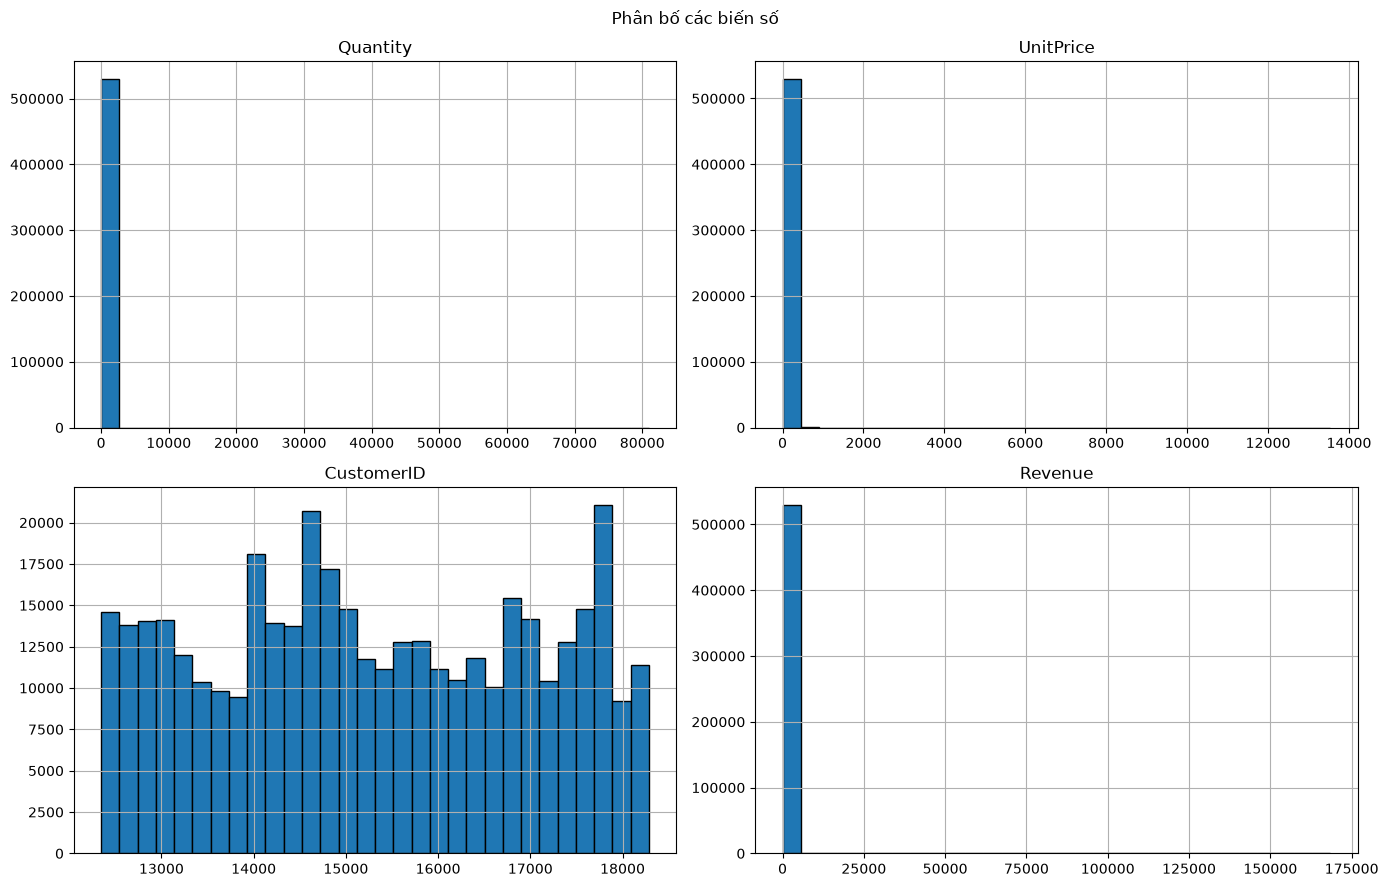

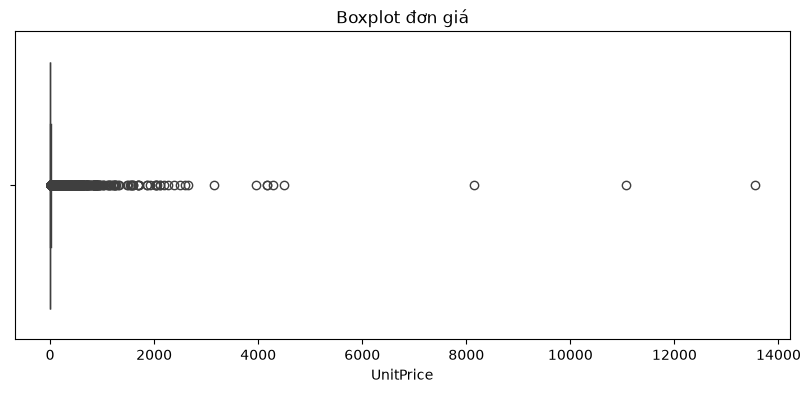

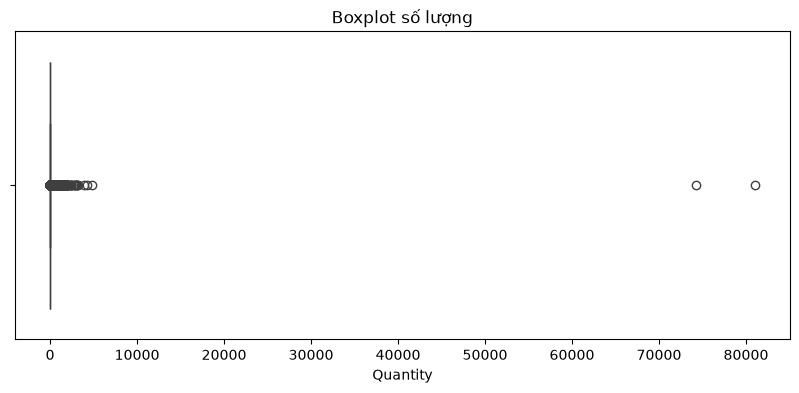

In [5]:
numeric_cols = valid.select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    display(valid[numeric_cols].describe().T)
    valid[numeric_cols].hist(figsize=(14, 9), bins=30, edgecolor="black")
    plt.suptitle("Phân bố các biến số")
    plt.tight_layout()
    plt.show()
if "UnitPrice" in valid.columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=valid["UnitPrice"])
    plt.title("Boxplot đơn giá")
    plt.show()
if "Quantity" in valid.columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=valid["Quantity"])
    plt.title("Boxplot số lượng")
    plt.show()

## 5. Phân tích doanh thu theo thời gian, sản phẩm, quốc gia

Tổng doanh thu (trên các dòng đã lọc): 10666684.54


,Month,Revenue
0,2010-12,823746.140
1,2011-01,691364.560
2,2011-02,523631.890
3,2011-03,717639.360
4,2011-04,537808.621


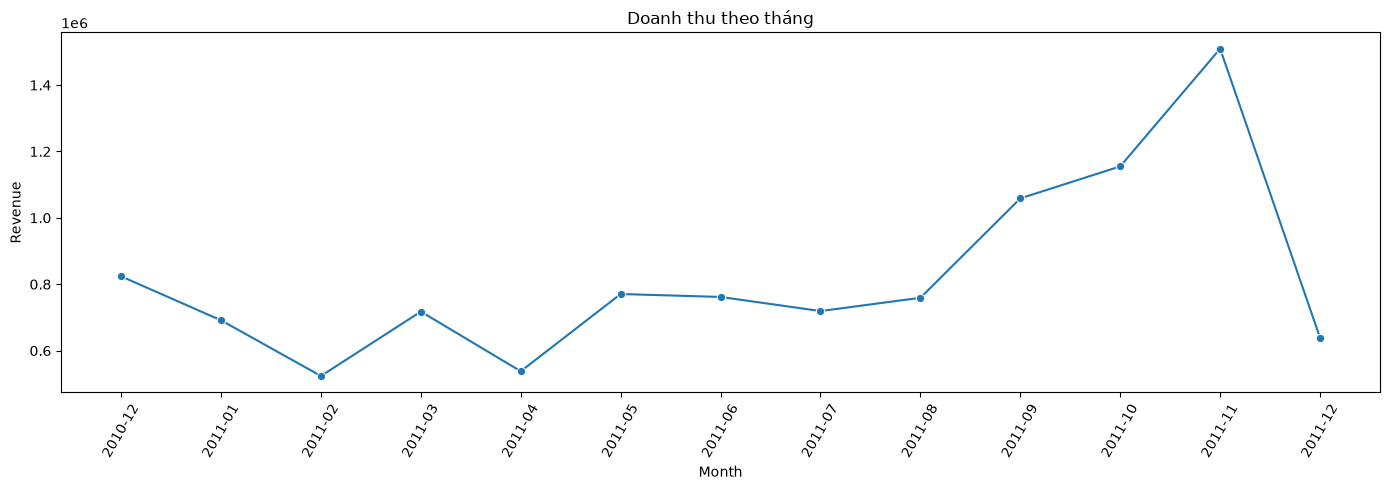

Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Australia          138521.310
Spain               61577.110
Switzerland         57089.900
Belgium             41196.340
Sweden              38378.330
Name: Revenue, dtype: float64

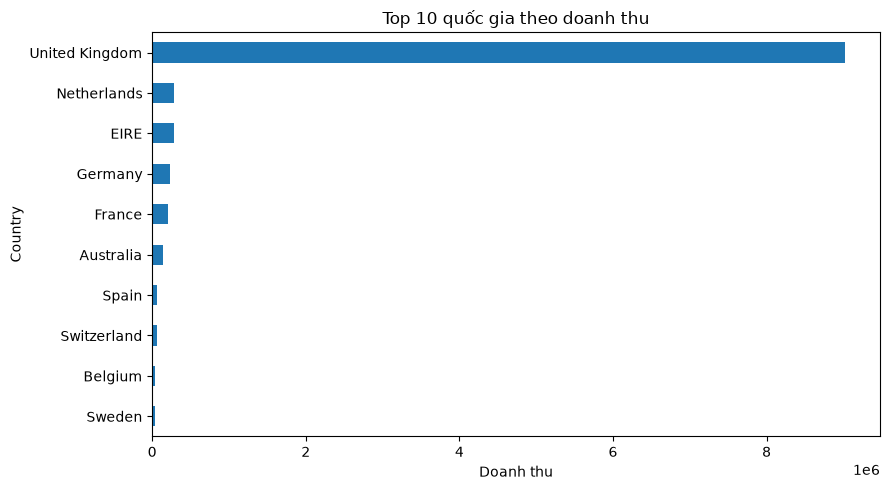

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: Revenue, dtype: float64

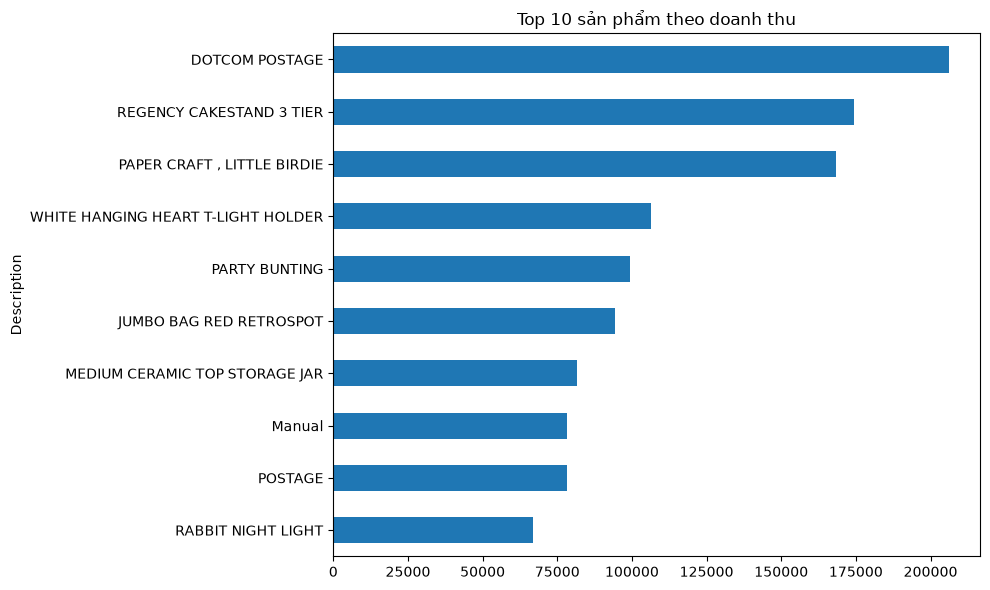

In [6]:
if "Revenue" in valid.columns:
    print("Tổng doanh thu (trên các dòng đã lọc):", round(valid["Revenue"].sum(), 2))
    if "InvoiceDate" in valid.columns:
        dated = valid.dropna(subset=["InvoiceDate"]).copy()
        dated["Month"] = dated["InvoiceDate"].dt.to_period("M").astype(str)
        monthly = dated.groupby("Month", as_index=False)["Revenue"].sum()
        display(monthly.head())
        plt.figure(figsize=(14, 5))
        sns.lineplot(data=monthly, x="Month", y="Revenue", marker="o")
        plt.xticks(rotation=60)
        plt.title("Doanh thu theo tháng")
        plt.tight_layout()
        plt.show()
    if "Country" in valid.columns:
        country_sales = valid.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)
        display(country_sales)
        country_sales.sort_values().plot(kind="barh", figsize=(9, 5))
        plt.title("Top 10 quốc gia theo doanh thu")
        plt.xlabel("Doanh thu")
        plt.tight_layout()
        plt.show()
    if "Description" in valid.columns:
        product_sales = valid.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)
        display(product_sales)
        product_sales.sort_values().plot(kind="barh", figsize=(10, 6))
        plt.title("Top 10 sản phẩm theo doanh thu")
        plt.tight_layout()
        plt.show()

## 6. Phân tích khách hàng và quan hệ giữa biến

,revenue,invoices
CustomerID,,
14646.0,280206.02,73
18102.0,259657.30,60
17450.0,194550.79,46
16446.0,168472.50,2
14911.0,143825.06,201
12415.0,124914.53,21
14156.0,117379.63,55
17511.0,91062.38,31
16029.0,81024.84,63


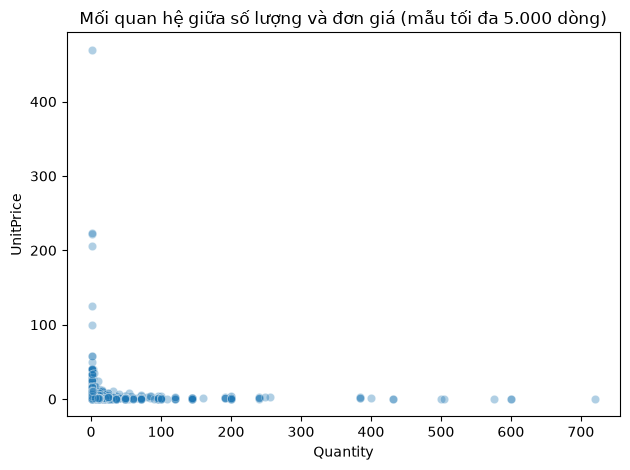

In [7]:
if "CustomerID" in valid.columns:
    customer = valid.dropna(subset=["CustomerID"]).groupby("CustomerID").agg(
        revenue=("Revenue", "sum") if "Revenue" in valid.columns else ("CustomerID", "size"),
        invoices=("InvoiceNo", "nunique") if "InvoiceNo" in valid.columns else ("CustomerID", "size")
    ).sort_values("revenue", ascending=False)
    display(customer.head(10))
if {"Quantity", "UnitPrice"}.issubset(valid.columns):
    sample = valid.sample(min(5000, len(valid)), random_state=42)
    sns.scatterplot(data=sample, x="Quantity", y="UnitPrice", alpha=.35)
    plt.title("Mối quan hệ giữa số lượng và đơn giá (mẫu tối đa 5.000 dòng)")
    plt.tight_layout()
    plt.show()

## 7. Kết luận và câu hỏi thảo luận
Sau khi chạy notebook, hãy ghi lại các kết quả thực tế:
1. Dữ liệu có bao nhiêu dòng/cột, biến nào thiếu nhiều nhất?
2. Có bao nhiêu dòng trùng lặp, giao dịch âm/0 và hóa đơn hủy?
3. Tháng nào có doanh thu cao nhất? Quốc gia/sản phẩm nào dẫn đầu?
4. Phân phối số lượng và đơn giá có lệch phải hoặc ngoại lai không?
5. Những bước làm sạch nào đã thực hiện và dữ liệu nào được giữ lại?

**Lưu ý:** `Revenue = Quantity × UnitPrice` là doanh thu dòng hàng trước khi áp dụng các quy tắc nghiệp vụ khác. Giao dịch có mã hóa đơn bắt đầu bằng `C` thường biểu thị hủy; cần kiểm tra và giải thích riêng, không âm thầm xóa khỏi dữ liệu gốc.